#### 1. Určení neznámé konstanty

- Určete konstantu c tak, aby f(x, y) = $cxy$ byla platnou hustotou pravděpodobnosti.

##### Řešení 

- konstanta `c` spočítaná ručně. Jednodušší by bylo použít `sympy`.

$$
1=\int_1^2\int_1^y cxy\,dx\,dy
=\frac c2\int_1^2 y(y^2-1)\,dy
=\frac c2\left[\frac{y^4}{4}-\frac{y^2}{2}\right]_1^2
=\frac{9c}{8} \implies c=\frac{8}{9}
$$

In [1]:
%matplotlib widget

from pathlib import Path
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
import numpy as np
import sympy as sp
from IPython.display import display
from scipy import stats

plt.close("all")
plt.style.use("default")

# Global styles for figures
# Disclaimer! AI was used for styling figures in code.
# Embed TrueType fonts in PDF exports so poster text stays editable and scalable.
plt.rcParams.update({
    "font.size": 14, "axes.titlesize": 18, "axes.labelsize": 16,
    "legend.fontsize": 12, "lines.linewidth": 2.5,
    "axes.spines.top": False, "axes.spines.right": False,
    "figure.facecolor": "white", "savefig.facecolor": "white",
    "pdf.fonttype": 42, "ps.fonttype": 42,
    "axes.prop_cycle": plt.cycler(color=["#0072B2", "#D55E00", "#009E73"]),
})
FIGURES_DIR = Path("figures")
FIGURES_DIR.mkdir(exist_ok=True)

DOMAIN_MIN = 1.0
DOMAIN_MAX = 2.0
# Keep the normalization constant exact during symbolic integration.
DENSITY_CONSTANT = sp.Rational(8, 9)
RANDOM_SEED = 42


def display_figure(figure, name):
    """Export each standalone panel at print quality and show it inline."""
    figure.tight_layout(pad=1.2)
    for extension in ("png", "pdf"):
        figure.savefig(FIGURES_DIR / f"{name}.{extension}", dpi=300,
                       bbox_inches="tight", pad_inches=0.15)
    display(figure)
    plt.close(figure)


def style_axis(axis, title, x_label, y_label, show_legend=True):
    """Use restrained grids and readable labels for poster panels."""
    axis.set(title=title, xlabel=x_label, ylabel=y_label)
    axis.set_axisbelow(True)
    axis.grid(axis="y", color="0.9", linewidth=0.7)
    axis.xaxis.set_major_locator(MaxNLocator(5))
    axis.yaxis.set_major_locator(MaxNLocator(5))
    if show_legend:
        axis.legend(frameon=False)


def evaluate_symbolic(expression, symbol, values):
    """Evaluate a SymPy expression on a NumPy array."""
    # Convert the symbolic formula to a vectorized NumPy function for plot grids.
    return np.asarray(sp.lambdify(symbol, expression, "numpy")(values), dtype=float)

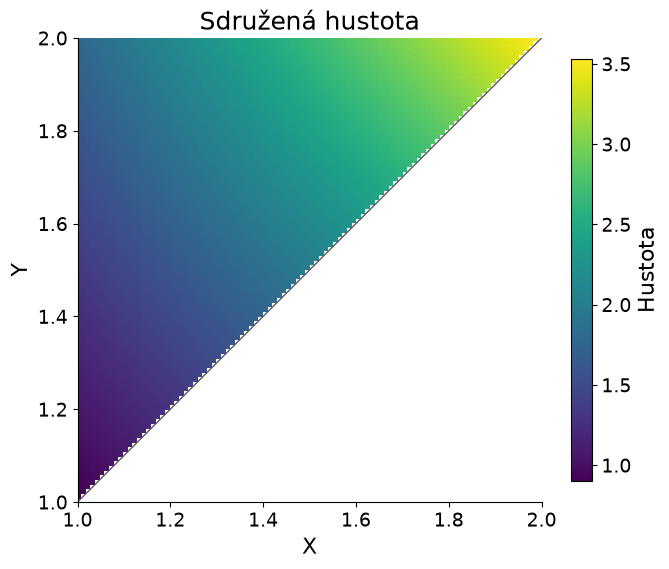

In [2]:
def joint_density(x_value, y_value):
    """Joint PDF on the triangular domain 1 < x < y < 2."""
    return sp.Piecewise(
        (DENSITY_CONSTANT * x_value * y_value,
         (x_value > 1) & (x_value < y_value) & (y_value < 2)),
        (0, True),
    )


def compute_joint_density_grid(density, grid_size=200):
    """Return grid coordinates and joint-density values for plotting."""
    x_symbol, y_symbol = sp.symbols("x y", real=True)
    coordinates = np.linspace(0.5, 2.5, grid_size)
    x_grid, y_grid = np.meshgrid(coordinates, coordinates)
    
    density_values = sp.lambdify(
        (x_symbol, y_symbol), density(x_symbol, y_symbol), "numpy"
    )(x_grid, y_grid)
    
    return x_grid, y_grid, density_values


def plot_joint_density(x_grid, y_grid, density_values):
    """Visualize the joint PDF as a heatmap of its triangular support."""
    with plt.ioff():
        figure, axis = plt.subplots(figsize=(7, 6))
        # Mask the zero-density exterior so the triangular support is clear.
        surface = axis.pcolormesh(x_grid, y_grid,
                                 np.ma.masked_where(density_values <= 0, density_values),
                                 cmap="viridis", shading="auto", rasterized=True)
        
        axis.plot([1, 2], [1, 2], color="0.35", linewidth=1)
        axis.set(xlim=(1, 2), ylim=(1, 2), xlabel="X", ylabel="Y",title="Sdružená hustota")
        axis.set_aspect("equal")
        
        figure.colorbar(surface, ax=axis, label="Hustota", shrink=0.85)
    display_figure(figure, "joint_density")

def task_1():
    joint_x_grid, joint_y_grid, joint_density_values = compute_joint_density_grid(joint_density)
    plot_joint_density(joint_x_grid, joint_y_grid, joint_density_values)
    
task_1()

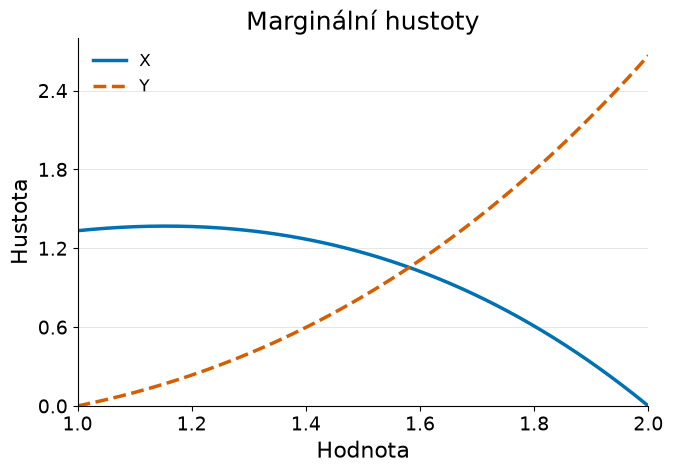

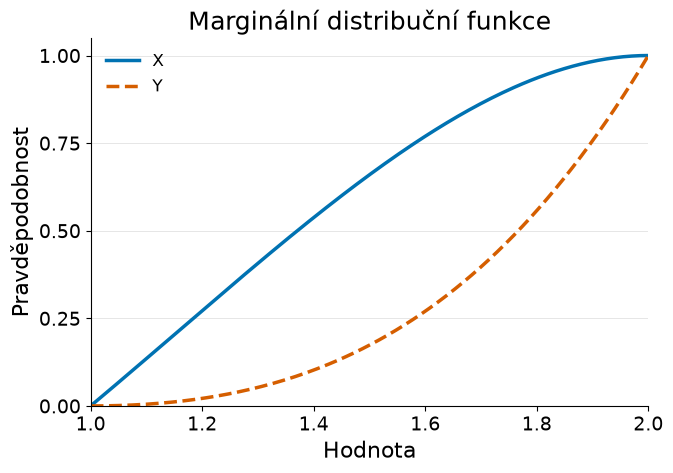

In [3]:
def calculate_marginal_densities(density):
    """Calculate symbolic marginal PDFs of X and Y."""
    x_symbol, y_symbol = sp.symbols("x y", real=True)
    joint_pdf = density(x_symbol, y_symbol)
    
    # The triangular support gives y in (x, 2) for fixed x, and x in (1, y) for fixed y.
    x_density = sp.integrate(joint_pdf, (y_symbol, x_symbol, 2))
    y_density = sp.integrate(joint_pdf, (x_symbol, 1, y_symbol))
    
    x_density = sp.Piecewise((x_density, (x_symbol > 1) & (x_symbol < 2)), (0, True))
    y_density = sp.Piecewise((y_density, (y_symbol > 1) & (y_symbol < 2)), (0, True))
    
    return x_density, y_density


def calculate_marginal_distributions(x_density, y_density):
    """Calculate symbolic marginal CDFs from the marginal PDFs."""
    x_symbol, y_symbol, integration_variable = sp.symbols("x y t", real=True)
    
    # Use a dummy integration variable so the upper bound remains the CDF argument.
    # Outside the support, the CDF is exactly 0 below 1 and exactly 1 above 2.
    x_cdf = sp.Piecewise(
        (0, x_symbol <= 1),
        (sp.integrate(x_density.subs(x_symbol, integration_variable),
                      (integration_variable, 1, x_symbol)), x_symbol < 2),
        (1, True),
    )
    
    y_cdf = sp.Piecewise(
        (0, y_symbol <= 1),
        (sp.integrate(y_density.subs(y_symbol, integration_variable),
                      (integration_variable, 1, y_symbol)), y_symbol < 2),
        (1, True),
    )
    
    return x_cdf, y_cdf


def compute_marginal_curves(x_density, y_density, x_cdf, y_cdf, grid_size=200):
    """Prepare marginal PDF/CDF data without altering the domain grid."""
    x_symbol, y_symbol = sp.symbols("x y", real=True)
    grid = np.linspace(DOMAIN_MIN, DOMAIN_MAX, grid_size)
    
    # nextafter evaluates PDFs just inside the open support: endpoint values of zero
    # would otherwise produce artificial vertical drops. CDFs use the exact endpoints.
    return {
        "grid": grid,
        "x_pdf": evaluate_symbolic(x_density, x_symbol, np.clip(grid, np.nextafter(1., 2.), np.nextafter(2., 1.))),
        "y_pdf": evaluate_symbolic(y_density, y_symbol, np.clip(grid, np.nextafter(1., 2.), np.nextafter(2., 1.))),
        "x_cdf": evaluate_symbolic(x_cdf, x_symbol, grid),
        "y_cdf": evaluate_symbolic(y_cdf, y_symbol, grid),
    }


def plot_marginals(curves):
    """Plot the marginal PDFs and CDFs."""
    for kind, title, ylabel in (
        ("pdf", "Marginální hustoty", "Hustota"),
        ("cdf", "Marginální distribuční funkce", "Pravděpodobnost"),
    ):
        with plt.ioff():
            figure, axis = plt.subplots(figsize=(7, 5))
            for label, linestyle in (("x", "-"), ("y", "--")):
                axis.plot(curves["grid"], curves[f"{label}_{kind}"],
                          linestyle=linestyle, label=label.upper())
            style_axis(axis, title, "Hodnota", ylabel)
            axis.set(xlim=(1, 2), ylim=(0, None))
        display_figure(figure, f"marginal_{kind}")

def task_2():
    x_density, y_density = calculate_marginal_densities(joint_density)
    x_cdf, y_cdf = calculate_marginal_distributions(x_density, y_density)
    marginal_curves = compute_marginal_curves(x_density, y_density, x_cdf, y_cdf)
    
    plot_marginals(marginal_curves)
    
task_2()

## Teoretické charakteristiky (střední hodnoty, rozptyly a kovariance (variační matici))

In [4]:
def calculate_means(x_density, y_density):
    """Calculate the theoretical means of X and Y."""
    x_symbol, y_symbol = sp.symbols("x y", real=True)
    
    expected_x = sp.integrate(x_symbol * x_density, (x_symbol, 1, 2))
    expected_y = sp.integrate(y_symbol * y_density, (y_symbol, 1, 2))
    
    return expected_x, expected_y


def calculate_variances(x_density, y_density, expected_x, expected_y):
    """Calculate theoretical variances using previously computed means."""
    x_symbol, y_symbol = sp.symbols("x y", real=True)
    
    expected_x_squared = sp.integrate(x_symbol**2 * x_density, (x_symbol, 1, 2))
    expected_y_squared = sp.integrate(y_symbol**2 * y_density, (y_symbol, 1, 2))
    
    # Var(X) = E[X^2] - E[X]^2; using exact symbolic values avoids rounding here.
    return expected_x_squared - expected_x**2, expected_y_squared - expected_y**2


def calculate_covariance(density, expected_x, expected_y):
    """Calculate theoretical covariance of X and Y."""
    x_symbol, y_symbol = sp.symbols("x y", real=True)
    
    joint_pdf = density(x_symbol, y_symbol)
    
    # X and Y are dependent, so E[XY] must be integrated over the joint support.
    expected_xy = sp.integrate(
        sp.integrate(x_symbol * y_symbol * joint_pdf, (y_symbol, x_symbol, 2)),
        (x_symbol, 1, 2),
    )
    
    return expected_xy - expected_x * expected_y


def calculate_covariance_matrix(variance_x, variance_y, covariance_xy):
    """Return the theoretical 2x2 covariance matrix."""
    return sp.Matrix([
        [variance_x, covariance_xy], 
        [covariance_xy, variance_y]
    ])


def print_theoretical_statistics(expected_x, expected_y, variance_x, variance_y,
                                 covariance_xy, covariance_matrix):
    """Display theoretical statistics separately from their calculation."""
    print(f"Mean of X: {expected_x}")
    print(f"Mean of Y: {expected_y}")
    print(f"Variance of X: {variance_x}")
    print(f"Variance of Y: {variance_y}")
    print(f"Covariance of X and Y: {covariance_xy}")
    print(f"Covariance matrix: {covariance_matrix}")

def task_3():
    x_density, y_density = calculate_marginal_densities(joint_density)
    expected_x, expected_y = calculate_means(x_density, y_density)
    
    variance_x, variance_y = calculate_variances(x_density, y_density, expected_x, expected_y)
    covariance_xy = calculate_covariance(joint_density, expected_x, expected_y)
    covariance_matrix = calculate_covariance_matrix(variance_x, variance_y, covariance_xy)
    
    print_theoretical_statistics(expected_x, expected_y, variance_x, variance_y, covariance_xy, covariance_matrix)

task_3()

Mean of X: 188/135
Mean of Y: 232/135
Variance of X: 1106/18225
Variance of Y: 851/18225
Covariance of X and Y: 484/18225
Covariance matrix: Matrix([[1106/18225, 484/18225], [484/18225, 851/18225]])


## Generování dat - zamítací metoda
#### dominující funkcí hustoty rovnoměrné rozdělení na intervalu <1,2> x <1,2>
#### konstanta *c* - maximální možná hodnota původní funkce

Acceptance rate: 0.2826 (theoretical: 0.2812)
Estimated E[X]: 1.3879 (theoretical: 1.3926)
Estimated E[Y]: 1.7146 (theoretical: 1.7185)
Estimated Var(X): 0.0602 (theoretical: 0.0607)
Estimated Var(Y): 0.0478 (theoretical: 0.0467)
Estimated Cov(X, Y): 0.02691 (theoretical: 0.02656)
Sample covariance matrix:
[[0.06024447 0.02690635]
 [0.02690635 0.04781977]]


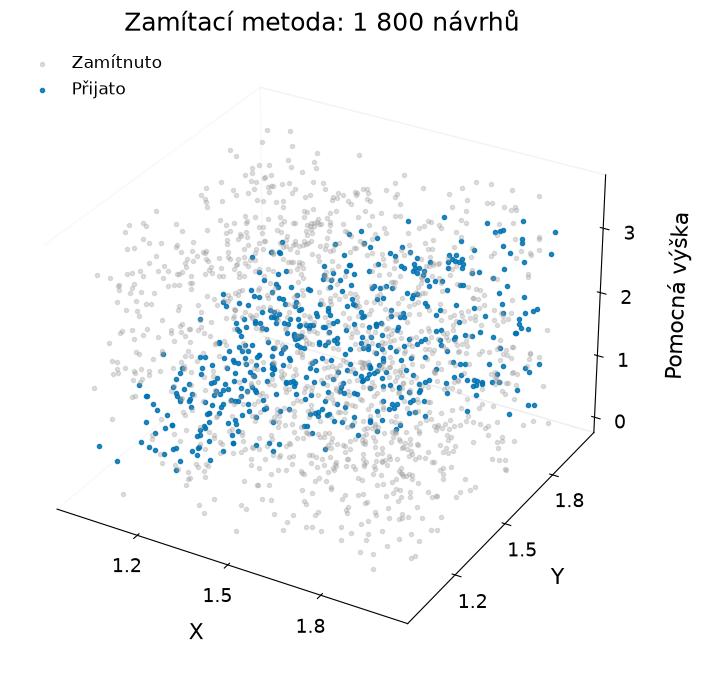

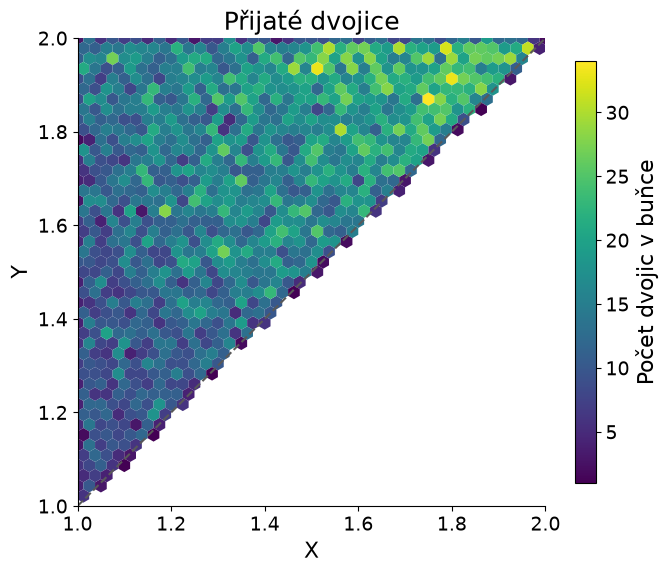

In [5]:
def generate_samples(proposal_count=50_000, seed=RANDOM_SEED):
    """Generate a joint sample by rejection sampling; return diagnostic points too."""
    if proposal_count < 1:
        raise ValueError("Proposal count must be positive.")
    
    generator = np.random.default_rng(seed)
    
    # c * 2^2 bounds the density everywhere in the unit proposal square.
    # Sampling uniformly under this envelope makes the accepted XY density proportional to f.
    envelope_height = float(DENSITY_CONSTANT) * DOMAIN_MAX**2
    
    proposed_x = generator.uniform(DOMAIN_MIN, DOMAIN_MAX, proposal_count)
    proposed_y = generator.uniform(DOMAIN_MIN, DOMAIN_MAX, proposal_count)
    proposed_z = generator.uniform(0, envelope_height, proposal_count)
    
    # Both conditions are needed: stay in the triangle and below the density surface.
    # Reuse the same mask for X and Y to retain their dependence.
    accepted_mask = ((proposed_x < proposed_y) & (proposed_z <= float(DENSITY_CONSTANT) * proposed_x * proposed_y))
    
    return {
        "x": proposed_x[accepted_mask],
        "y": proposed_y[accepted_mask],
        "proposed_x": proposed_x,
        "proposed_y": proposed_y,
        "proposed_z": proposed_z,
        "accepted_mask": accepted_mask,
        "acceptance_rate": float(accepted_mask.mean()),
    }

def calculate_sample_statistics(x_samples, y_samples):
    """Calculate sample means and the unbiased sample covariance matrix."""
    # Rows are variables and columns are paired observations; off-diagonal entries
    # estimate Cov(X, Y), while the diagonal contains the sample variances.
    covariance_matrix = np.cov(np.vstack((x_samples, y_samples)), ddof=1)
    # ddof=1 divides by n-1, giving the unbiased sample variance.
    return {
        "mean_x": float(np.mean(x_samples)),
        "mean_y": float(np.mean(y_samples)),
        "variance_x": float(np.var(x_samples, ddof=1)),
        "variance_y": float(np.var(y_samples, ddof=1)),
        "covariance_xy": float(covariance_matrix[0, 1]),
        "covariance_matrix": covariance_matrix,
    }


def print_sampling_summary(samples, statistics, expected_x, expected_y, variance_x, variance_y, covariance_xy):
    """Print rejection-sampling diagnostics."""
    print(f"Acceptance rate: {samples['acceptance_rate']:.4f} (theoretical: {9/32:.4f})")
    print(f"Estimated E[X]: {statistics['mean_x']:.4f} (theoretical: {float(expected_x):.4f})")
    print(f"Estimated E[Y]: {statistics['mean_y']:.4f} (theoretical: {float(expected_y):.4f})")
    print(f"Estimated Var(X): {statistics['variance_x']:.4f} (theoretical: {float(variance_x):.4f})")
    print(f"Estimated Var(Y): {statistics['variance_y']:.4f} (theoretical: {float(variance_y):.4f})")
    print(f"Estimated Cov(X, Y): {statistics['covariance_xy']:.5f} (theoretical: {float(covariance_xy):.5f})")
    print(f"Sample covariance matrix:\n{statistics['covariance_matrix']}")


def plot_rejection_sampling(samples):
    """Visualize accepted/rejected proposals and accepted XY pairs."""
    # A reproducible subset shows the method without an opaque cloud of points.
    indices = np.random.default_rng(RANDOM_SEED).choice(
        len(samples["proposed_x"]), min(1800, len(samples["proposed_x"])), replace=False)
    
    with plt.ioff():
        figure = plt.figure(figsize=(8, 7))
        axis = figure.add_subplot(111, projection="3d")
    
        for accepted, color, label in ((False, "#999999", "Zamítnuto"), (True, "#0072B2", "Přijato")):
            selected = indices[samples["accepted_mask"][indices] == accepted]
            axis.scatter(samples["proposed_x"][selected], samples["proposed_y"][selected],
                         samples["proposed_z"][selected], color=color, s=9,
                         alpha=0.85 if accepted else 0.3, depthshade=False,
                         label=label, rasterized=True)
       
        axis.set(xlabel="X", ylabel="Y", zlabel="Pomocná výška", title="Zamítací metoda: 1 800 návrhů")
        axis.grid(False)
        
        for coordinate_axis in (axis.xaxis, axis.yaxis, axis.zaxis):
            coordinate_axis.pane.fill = False
            coordinate_axis.labelpad = 14
       
        axis.xaxis.set_major_locator(MaxNLocator(4))
        axis.yaxis.set_major_locator(MaxNLocator(4))
        axis.zaxis.set_major_locator(MaxNLocator(4))
        axis.legend(frameon=False, loc="upper left")
    
    display_figure(figure, "rejection_sampling")
    
    with plt.ioff():
        figure, axis = plt.subplots(figsize=(7, 6))
        # Bin all accepted pairs to show concentration without overlapping thousands of dots.
        # Rasterize the dense artist in PDF exports while keeping axes and text as vectors.
        density = axis.hexbin(samples["x"], samples["y"], gridsize=40,
                              extent=(1, 2, 1, 2), mincnt=1, cmap="viridis",
                              linewidths=0, rasterized=True)
        
        axis.plot([1, 2], [1, 2], color="0.35", linestyle="--", linewidth=1.5)
        axis.set(xlim=(1, 2), ylim=(1, 2), aspect="equal")
        
        style_axis(axis, "Přijaté dvojice", "X", "Y", show_legend=False)
        
        axis.grid(False)
        figure.colorbar(density, ax=axis, label="Počet dvojic v buňce", shrink=0.85)
    
    display_figure(figure, "accepted_pairs")

def task_4():
    samples = generate_samples()
    x_samples, y_samples = samples["x"], samples["y"]
    x_density, y_density = calculate_marginal_densities(joint_density)
    
    sample_statistics = calculate_sample_statistics(x_samples, y_samples)
    
    expected_x, expected_y = calculate_means(x_density, y_density)
    variance_x, variance_y = calculate_variances(x_density, y_density, expected_x, expected_y)
       
    covariance_xy = calculate_covariance(joint_density, expected_x, expected_y)

    print_sampling_summary(samples, sample_statistics, expected_x, expected_y, variance_x, variance_y, covariance_xy)
    plot_rejection_sampling(samples)
    
task_4()

## Intervalové odhady

#### IS pro střední hodnotu: $ X\pm t_{1-\alpha/2}\,\frac{S_X}{\sqrt n}$

#### IS pro rozptyl: $\left( \frac{(n-1) S^2}{\chi^2_{1-\alpha/2}(n-1)}, \quad \frac{(n-1) S^2}{\chi^2_{\alpha/2}(n-1)} \right)$

In [6]:
def calculate_mean_confidence_interval(values, alpha=0.05):
    """Calculate a Student-t confidence interval for the population mean."""
    values = np.asarray(values, dtype=float)
    count = len(values)
    if count < 2:
        raise ValueError("At least two observations are required.")
    
    sample_mean = values.mean()
    sample_std = values.std(ddof=1)
    
    # Split alpha between both tails and estimate the unknown standard deviation.
    # The t interval is exact for normal data; here it is a large-sample approximation.
    critical_value = stats.t.ppf(1 - alpha / 2, df=count - 1)
    
    margin = critical_value * sample_std / np.sqrt(count)
    return float(sample_mean), (float(sample_mean - margin), float(sample_mean + margin))


def calculate_variance_confidence_interval(values, alpha=0.05):
    """Compute a chi-square-based variance CI (exact only for normal data)."""
    values = np.asarray(values, dtype=float)
    count = len(values)
    if count < 2:
        raise ValueError("At least two observations are required.")
    
    sample_variance = values.var(ddof=1)
    lower_quantile = stats.chi2.ppf(alpha / 2, df=count - 1)
    upper_quantile = stats.chi2.ppf(1 - alpha / 2, df=count - 1)
    
    # Inverting the chi-square pivot reverses the quantiles in the denominators.
    # Our marginals are not normal, so this interval has no exact coverage guarantee.
    return float(sample_variance), (
        float((count - 1) * sample_variance / upper_quantile),
        float((count - 1) * sample_variance / lower_quantile),
    )


def calculate_confidence_intervals(x_values, y_values, alpha=0.05):
    """Return point estimates and confidence intervals for both variables."""
    results = {}
    
    for label, values in (("X", x_values), ("Y", y_values)):
        mean_estimate, mean_interval = calculate_mean_confidence_interval(values, alpha)
        variance_estimate, variance_interval = calculate_variance_confidence_interval(values, alpha)
    
        results[label] = {
            "mean": mean_estimate,
            "mean_interval": mean_interval,
            "variance": variance_estimate,
            "variance_interval": variance_interval,
        }
    
    return results


def print_confidence_intervals(interval_results, theoretical_values, confidence_level=0.95):
    """Display interval estimates without mixing them into calculation functions."""
    for label in ("X", "Y"):
        
        result = interval_results[label]
        
        for statistic_name in ("mean", "variance"):
            lower, upper = result[f"{statistic_name}_interval"]
            true_value = theoretical_values[label][statistic_name]
        
            print(f"{confidence_level:.0%} CI for {statistic_name} of {label}: "f"({lower:.5f}, {upper:.5f})")
            print(f"Theoretical value: {float(true_value):.5f}")

def task_5():  
    samples = generate_samples()
    
    x_samples, y_samples = samples["x"], samples["y"]
    x_density, y_density = calculate_marginal_densities(joint_density)
    
    expected_x, expected_y = calculate_means(x_density, y_density)
    variance_x, variance_y = calculate_variances(x_density, y_density, expected_x, expected_y)
      
    theoretical_values = {
        "X": {"mean": expected_x, "variance": variance_x},
        "Y": {"mean": expected_y, "variance": variance_y},
    }
    
    confidence_results = calculate_confidence_intervals(x_samples, y_samples)
    
    print_confidence_intervals(confidence_results, theoretical_values)
    
task_5()

95% CI for mean of X: (1.38381, 1.39190)
Theoretical value: 1.39259
95% CI for variance of X: (0.05886, 0.06167)
Theoretical value: 0.06069
95% CI for mean of Y: (1.71098, 1.71819)
Theoretical value: 1.71852
95% CI for variance of Y: (0.04672, 0.04895)
Theoretical value: 0.04669


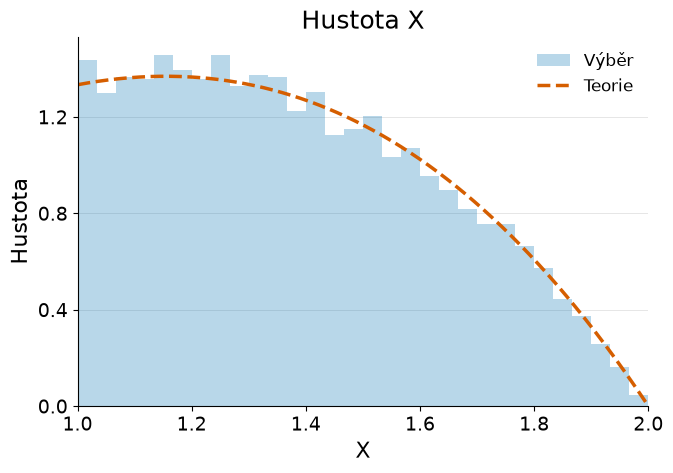

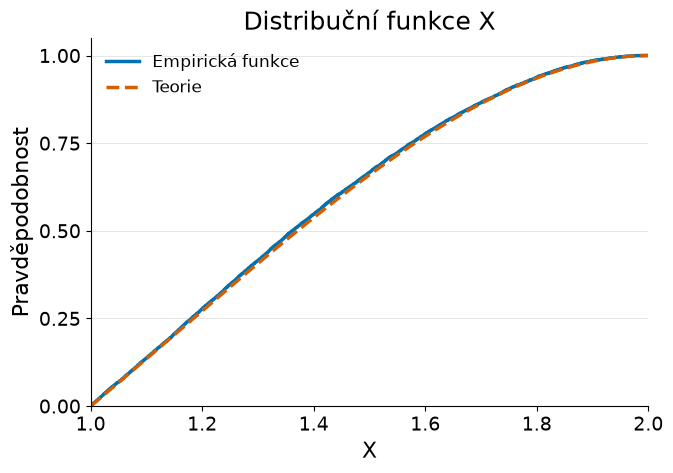

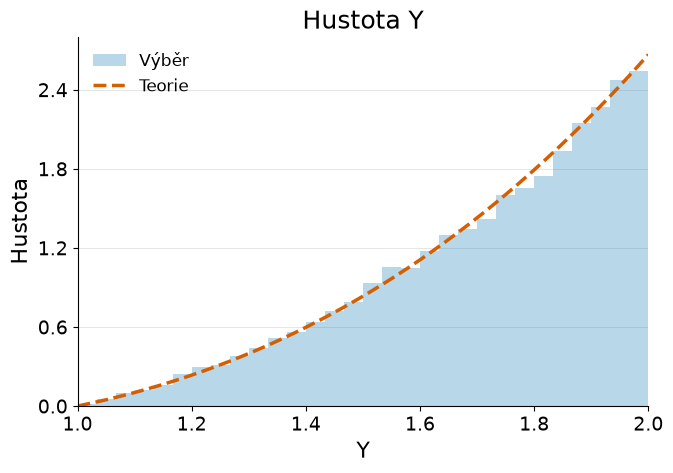

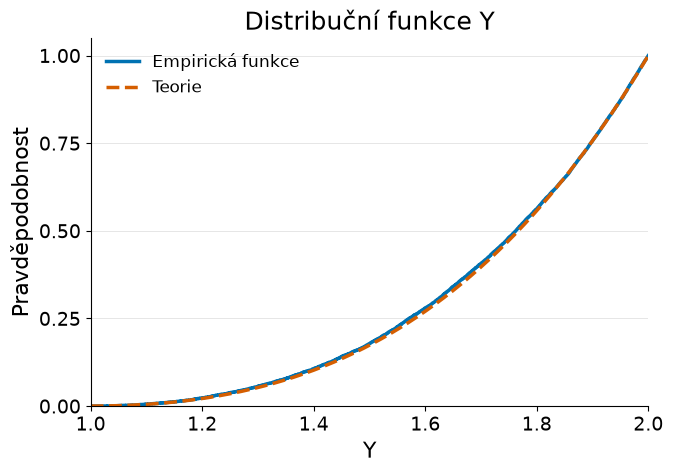

In [7]:
def calculate_empirical_distribution(values):
    """Return coordinates of the empirical cumulative distribution function."""
    sorted_values = np.sort(np.asarray(values, dtype=float))
    # At the i-th ordered observation, i/n of the sample is at or below that value.
    cumulative_probabilities = np.arange(1, len(sorted_values) + 1) / len(sorted_values)
    return sorted_values, cumulative_probabilities


def compute_distribution_comparison(x_values, y_values, x_density, y_density, x_distribution, y_distribution, grid_size=500):
    """Prepare empirical and theoretical PDF/CDF data for Task 6."""
    x_symbol, y_symbol = sp.symbols("x y", real=True)
    grid = np.linspace(DOMAIN_MIN, DOMAIN_MAX, grid_size)
    
    comparison = {}
    for label, values, symbol, density, distribution in (
        ("X", x_values, x_symbol, x_density, x_distribution),
        ("Y", y_values, y_symbol, y_density, y_distribution),
    ):
        sorted_values, empirical_cdf = calculate_empirical_distribution(values)
        
        # Match the PDF endpoint convention used for the theoretical marginal plots.
        comparison[label] = {
            "samples": np.asarray(values, dtype=float),
            "grid": grid,
            "pdf": evaluate_symbolic(density, symbol, np.clip(grid, np.nextafter(1., 2.), np.nextafter(2., 1.))),
            "cdf": evaluate_symbolic(distribution, symbol, grid),
            "sorted_samples": sorted_values,
            "empirical_cdf": empirical_cdf,
        }
        
    return comparison


def plot_empirical_vs_theoretical(comparison):
    """Visualize empirical and theoretical distributions for Task 6."""
    for label, data in comparison.items():
        for kind in ("pdf", "cdf"):
            with plt.ioff():
                figure, axis = plt.subplots(figsize=(7, 5))
                if kind == "pdf":
                    axis.hist(data["samples"], bins=30, range=(1, 2), density=True, color="#0072B2", alpha=0.28, label="Výběr")
                    ylabel = "Hustota"
                else:
                    # Extend the step curve to (1, 0) and (2, 1); post makes it right-continuous.
                    axis.step(np.r_[1, data["sorted_samples"], 2],
                              np.r_[0, data["empirical_cdf"], 1], where="post",
                              color="#0072B2", label="Empirická funkce")
                    ylabel = "Pravděpodobnost"
                
                axis.plot(data["grid"], data[kind], color="#D55E00", linestyle="--", label="Teorie")
                style_axis(axis, f"{'Hustota' if kind == 'pdf' else 'Distribuční funkce'} {label}", label, ylabel)
                axis.set(xlim=(1, 2), ylim=(0, None))
            
            display_figure(figure, f"comparison_{label.lower()}_{kind}")

def task_6():
    samples = generate_samples()
        
    x_samples, y_samples = samples["x"], samples["y"]
    x_density, y_density = calculate_marginal_densities(joint_density)
    x_cdf, y_cdf = calculate_marginal_distributions(x_density, y_density)
    
    comparison = compute_distribution_comparison(x_samples, y_samples, x_density, y_density, x_cdf, y_cdf)
    
    plot_empirical_vs_theoretical(comparison)
    
task_6()

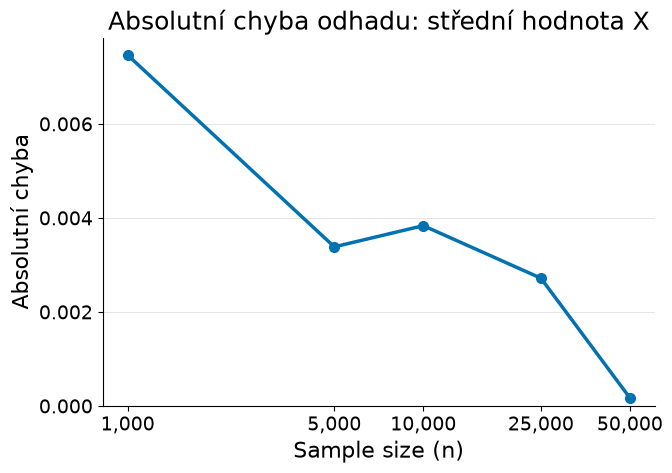

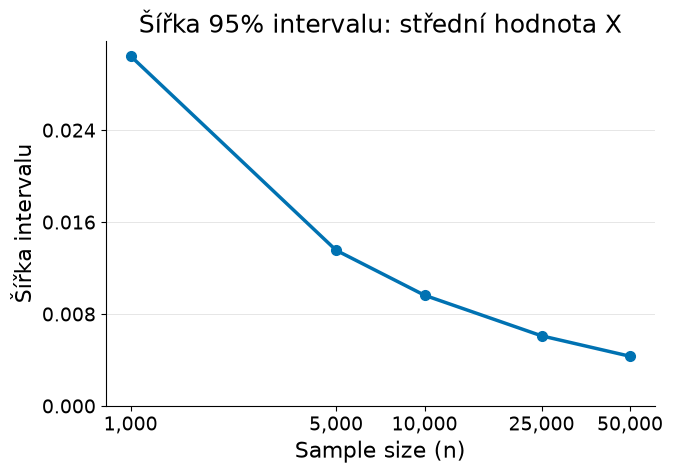

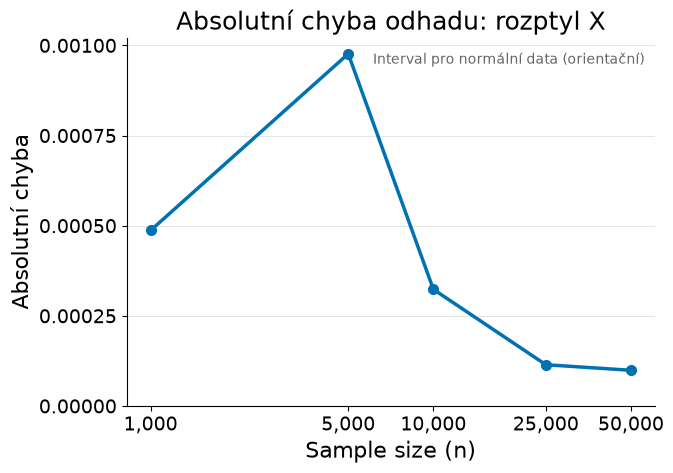

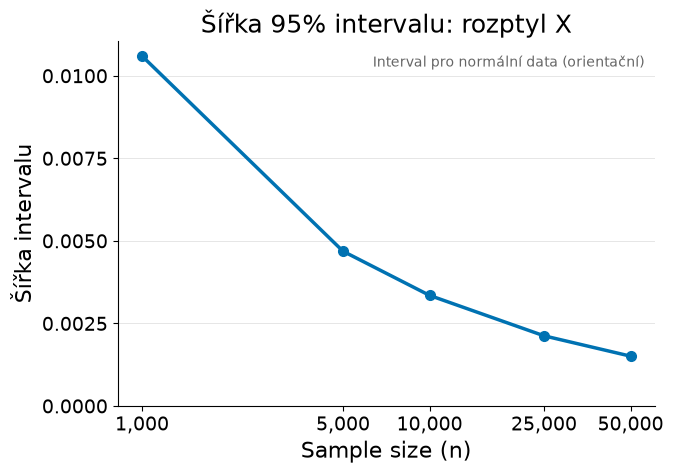

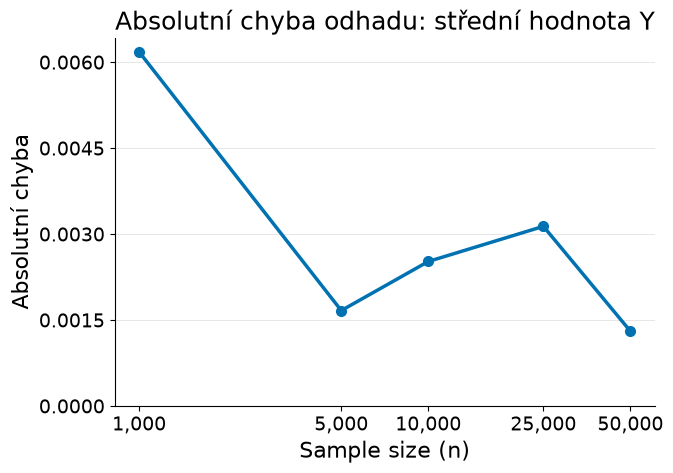

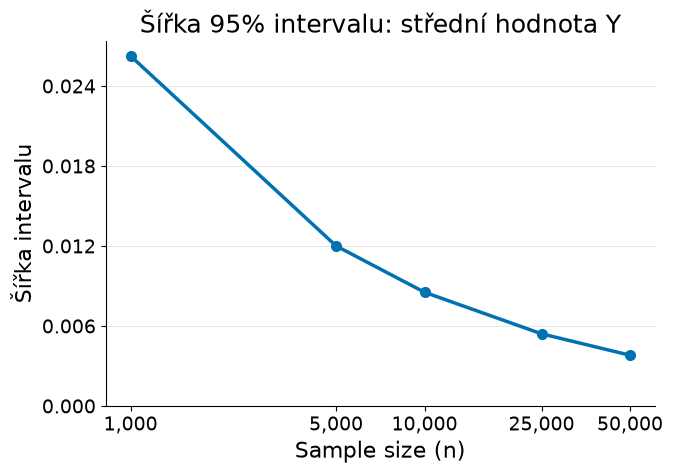

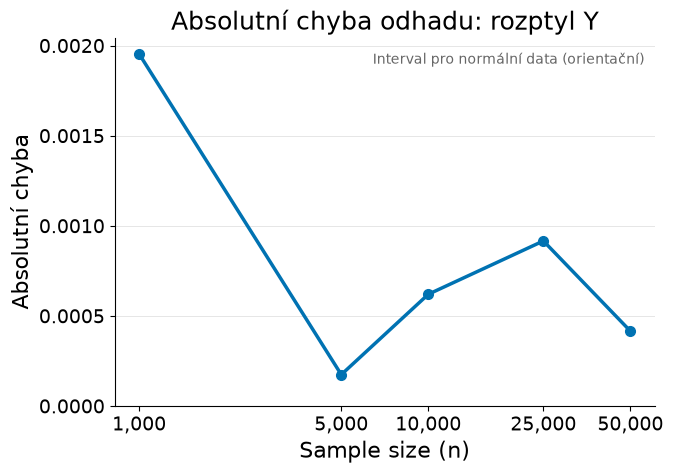

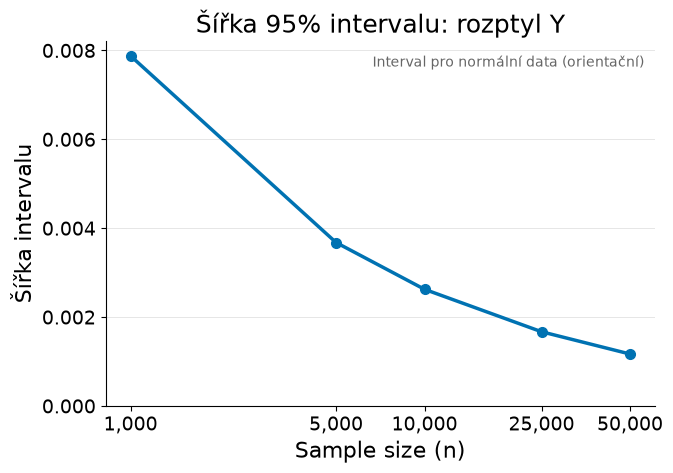

In [8]:
def calculate_estimation_accuracy(x_values, y_values, sample_sizes,theoretical_values, alpha=0.05):
    """Recompute Task 5 estimates/CIs on growing prefixes of Task 4's sample."""
    x_values = np.asarray(x_values, dtype=float)
    y_values = np.asarray(y_values, dtype=float)

    # ----- WARNING, a lot of sanity checks :-)) -----     
    if len(x_values) != len(y_values):
        raise ValueError("X and Y must contain the same number of observations.")

    # Validate before casting: converting 2.5 directly to int would silently turn it into 2.
    raw_sizes = np.asarray(sample_sizes)
    if (raw_sizes.ndim != 1 or raw_sizes.size == 0
            or not np.issubdtype(raw_sizes.dtype, np.number)
            or not np.all(np.isfinite(raw_sizes))
            or np.any(raw_sizes != np.floor(raw_sizes))):
        raise ValueError("Sample sizes must be a nonempty sequence of finite integers.")
    
    sizes = raw_sizes.astype(int)
    
    if np.any(sizes < 2) or np.any(sizes > len(x_values)):
        raise ValueError("Sample sizes must lie between 2 and the available sample count.")
    
    if len(np.unique(sizes)) != len(sizes):
        raise ValueError("Sample sizes must be unique.")
    # ----------------- Finished -----------------
    
    
    sizes = np.sort(sizes)
    results = {}
    
    for label, values in (("X", x_values), ("Y", y_values)):
        for parameter in ("mean", "variance"):
            estimates, intervals = [], []
            for size in sizes:
                # Nested prefixes isolate the effect of adding observations to the same sample.
                # These estimates share observations, so they are not independent repetitions.
                subset = values[:size]
                
                if parameter == "mean":
                    estimate, interval = calculate_mean_confidence_interval(subset, alpha)
                
                else:
                    estimate, interval = calculate_variance_confidence_interval(subset, alpha)
                
                estimates.append(estimate)
                intervals.append(interval)
            
            results[f"{label}_{parameter}"] = {
                "sample_sizes": sizes.copy(),
                "estimates": np.asarray(estimates),
                "confidence_intervals": np.asarray(intervals),
                "theoretical_value": float(theoretical_values[label][parameter]),
                "parameter_name": f"{parameter.title()} of {label}",
            }
            
    return results


def plot_estimation_accuracy(accuracy_data):
    """Visualize estimation errors and confidence interval widths for Task 7."""
    sample_sizes = accuracy_data["sample_sizes"]
    estimates = accuracy_data["estimates"]
    intervals = accuracy_data["confidence_intervals"]
    theoretical_value = accuracy_data["theoretical_value"]
    parameter_name = accuracy_data["parameter_name"]
    
    absolute_errors = np.abs(estimates - theoretical_value)
    interval_widths = intervals[:, 1] - intervals[:, 0]
    name = parameter_name.lower().replace(" of ", "_")
    parameter_title = parameter_name.replace("Mean of", "střední hodnota").replace("Variance of", "rozptyl")
    
    for metric, values, title, ylabel in (
        ("error", absolute_errors, "Absolutní chyba odhadu", "Absolutní chyba"),
        ("ci_width", interval_widths, "Šířka 95% intervalu", "Šířka intervalu"),
    ):
        with plt.ioff():
            figure, axis = plt.subplots(figsize=(7, 5))
            axis.plot(sample_sizes, values, marker="o", markersize=7)
            style_axis(axis, f"{title}: {parameter_title}", "Sample size (n)", ylabel, show_legend=False)
            
            # A log axis separates the smaller sizes while showing the full 1,000-50,000 range.
            axis.set_xscale("log")
            axis.set_xticks(sample_sizes, [f"{n:,}" for n in sample_sizes])
            axis.minorticks_off()
            axis.set_ylim(bottom=0)
            
            if name.startswith("variance"):
                axis.text(0.98, 0.96, "Interval pro normální data (orientační)", transform=axis.transAxes, ha="right", va="top", fontsize=10, color="0.4")
        
        display_figure(figure, f"accuracy_{name}_{metric}")


def ensure_sample_count(samples, required_count, seed=RANDOM_SEED + 1):
    """Append rejection batches until enough accepted pairs are available.

    Keep the original sample as a prefix and preserve X/Y pairing. Proposal
    counts are distinct from accepted sample sizes; no requested sizes are clipped.
    """
    generator = np.random.default_rng(seed)
    keys = ("x", "y", "proposed_x", "proposed_y", "proposed_z", "accepted_mask")
    batches = [samples]
    count = len(samples["x"])
    
    while count < required_count:
        # Acceptance probability = integral(f) / envelope volume = 1 / (32/9) = 9/32.
        # Allow 5% extra proposals; the loop handles random shortfalls in accepted counts.
        proposal_count = max(1000, int(np.ceil((required_count - count) / (9 / 32) * 1.05)))
        
        # Reproducible but different batch seeds prevent repeating the same random points.
        batch = generate_samples(proposal_count, seed=int(generator.integers(0, 2**32)))
        batches.append(batch)
        count += len(batch["x"])
    
    if len(batches) == 1:
        return samples
    
    combined = {key: np.concatenate([batch[key] for batch in batches]) for key in keys}
    
    # Recompute from every proposal rather than averaging rates of unequal-sized batches.
    combined["acceptance_rate"] = float(combined["accepted_mask"].mean())
    return combined

def task_7():
    samples = generate_samples()
    
    x_density, y_density = calculate_marginal_densities(joint_density)
    
    expected_x, expected_y = calculate_means(x_density, y_density)
    variance_x, variance_y = calculate_variances(x_density, y_density, expected_x, expected_y)
        
    theoretical_values = {
        "X": {"mean": expected_x, "variance": variance_x},
        "Y": {"mean": expected_y, "variance": variance_y},
    }
    
    sample_sizes = [1_000, 5_000, 10_000, 25_000, 50_000]

    # Requested sizes count accepted pairs, not proposals; extend only the Task 7 sample.
    accuracy_samples = ensure_sample_count(samples, max(sample_sizes))
    accuracy_results = calculate_estimation_accuracy(accuracy_samples["x"], accuracy_samples["y"], sample_sizes, theoretical_values)

    for parameter_data in accuracy_results.values():
        plot_estimation_accuracy(parameter_data)
        
task_7()

## 8. Souhrn výsledků pro poster

Porovnání teoretických a výběrových charakteristik, intervaly pro střední hodnoty a přehled přesnosti. Číselné výsledky se exportují i pro sestavení posteru v TeXu.


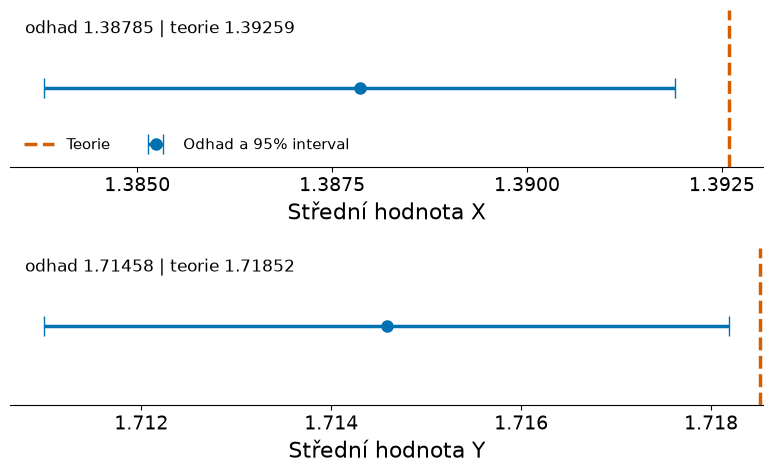

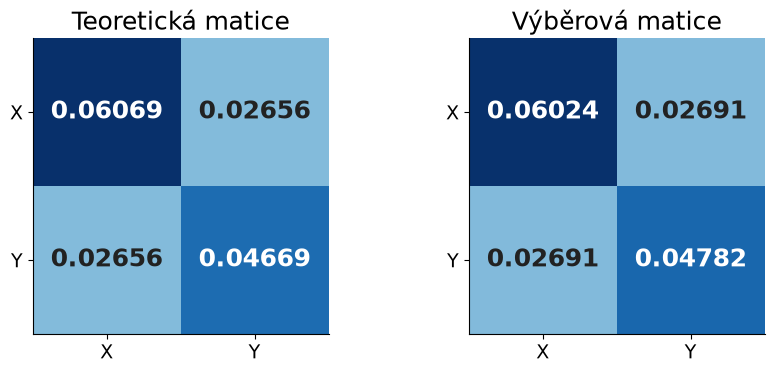

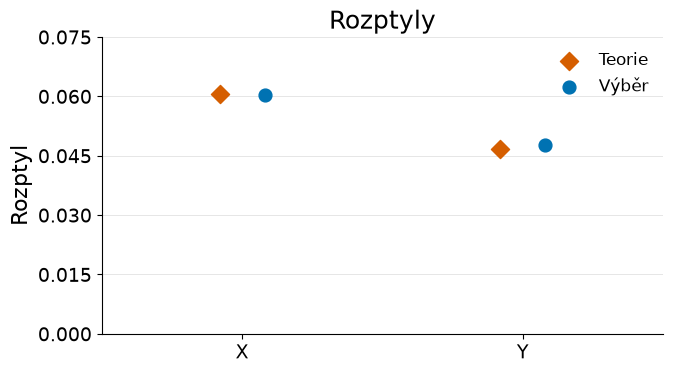

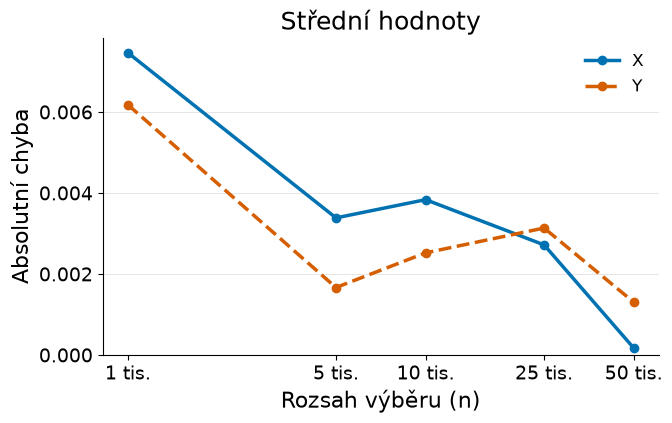

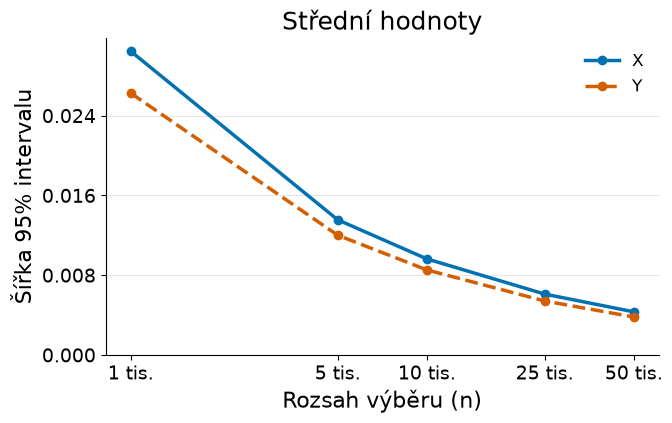

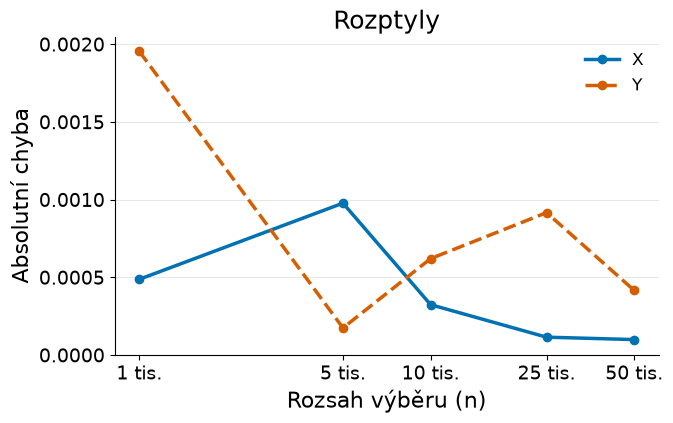

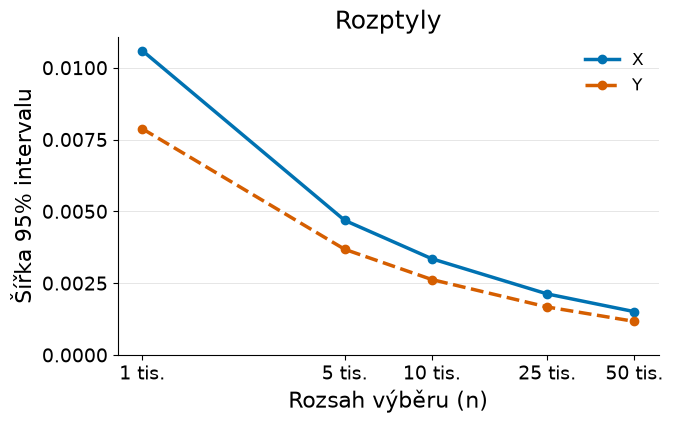

In [9]:
def plot_mean_estimates(interval_results, theoretical_values):
    """Compare each sample mean and its 95% interval with the theoretical mean."""
    with plt.ioff():
        figure, axes = plt.subplots(2, 1, figsize=(8, 5))

        for axis, label in zip(axes, ("X", "Y")):
            estimate = interval_results[label]["mean"]
            lower, upper = interval_results[label]["mean_interval"]
            truth = float(theoretical_values[label]["mean"])

            # Separate scales reveal the small deviations for both means without
            # hiding them in the much larger distance between E[X] and E[Y].
            axis.errorbar(estimate, 0, xerr=[[estimate - lower], [upper - estimate]],
                          fmt="o", color="#0072B2", capsize=7, markersize=8,
                          label="Odhad a 95% interval")
            axis.axvline(truth, color="#D55E00", linestyle="--", label="Teorie")
            axis.set_yticks([])
            axis.set_ylim(-0.6, 0.6)
            axis.set_xlabel(f"Střední hodnota {label}")
            axis.xaxis.set_major_locator(MaxNLocator(4))
            axis.spines["left"].set_visible(False)
            axis.text(0.02, 0.85, f"odhad {estimate:.5f} | teorie {truth:.5f}",
                      transform=axis.transAxes, fontsize=12)

        axes[0].legend(frameon=False, loc="lower left", ncol=2, fontsize=11)

    display_figure(figure, "mean_estimates")


def plot_covariance_estimates(sample_matrix, theoretical_matrix):
    """Display theory and sample covariance on the same numerical color scale."""
    from matplotlib.colors import Normalize

    matrices = (np.asarray(theoretical_matrix, dtype=float), sample_matrix)
    normalization = Normalize(vmin=0, vmax=max(matrix.max() for matrix in matrices))

    with plt.ioff():
        figure, axes = plt.subplots(1, 2, figsize=(9, 4))

        for axis, matrix, title in zip(axes, matrices, ("Teoretická matice", "Výběrová matice")):
            axis.imshow(matrix, cmap="Blues", norm=normalization)
            axis.set_xticks([0, 1], ["X", "Y"])
            axis.set_yticks([0, 1], ["X", "Y"])
            axis.set_title(title)

            # Exact cell values are more useful here than a redundant colorbar.
            for row in range(2):
                for column in range(2):
                    value = matrix[row, column]
                    axis.text(column, row, f"{value:.5f}", ha="center", va="center",
                              color="white" if normalization(value) > 0.55 else "#222222",
                              fontsize=18, fontweight="bold")

    display_figure(figure, "covariance_estimates")


def plot_variance_estimates(statistics, theoretical_values):
    """Compare the diagonal entries of the covariance matrices directly."""
    with plt.ioff():
        figure, axis = plt.subplots(figsize=(7, 4))

        for position, label in enumerate(("X", "Y")):
            axis.scatter(position - 0.08, float(theoretical_values[label]["variance"]),
                         marker="D", s=85, color="#D55E00",
                         label="Teorie" if position == 0 else None)
            axis.scatter(position + 0.08, statistics[f"variance_{label.lower()}"],
                         s=85, color="#0072B2", label="Výběr" if position == 0 else None)

        style_axis(axis, "Rozptyly", "", "Rozptyl")
        axis.set_xticks([0, 1], ["X", "Y"])
        axis.set(xlim=(-0.5, 1.5), ylim=(0, 0.075))

    display_figure(figure, "variance_estimates")


def plot_accuracy_summary(accuracy_results):
    """Overlay X and Y in compact poster panels, keeping individual exports too."""
    for parameter, title in (("mean", "Střední hodnoty"), ("variance", "Rozptyly")):
        for metric, ylabel in (("error", "Absolutní chyba"), ("ci_width", "Šířka 95% intervalu")):
            with plt.ioff():
                figure, axis = plt.subplots(figsize=(7, 4.5))

                for label, linestyle in (("X", "-"), ("Y", "--")):
                    data = accuracy_results[f"{label}_{parameter}"]
                    sizes = data["sample_sizes"]
                    intervals = data["confidence_intervals"]
                    values = (np.abs(data["estimates"] - data["theoretical_value"])
                              if metric == "error" else intervals[:, 1] - intervals[:, 0])
                    axis.plot(sizes, values, marker="o", linestyle=linestyle, label=label)

                style_axis(axis, title, "Rozsah výběru (n)", ylabel)
                axis.set_xscale("log")
                axis.set_xticks(sizes, [f"{size // 1000} tis." for size in sizes])
                axis.minorticks_off()
                axis.set_ylim(bottom=0)

            display_figure(figure, f"summary_{parameter}_{metric}")


def export_poster_results(samples, statistics, theoretical_values, theoretical_matrix,
                          intervals, accuracy_results, comparison):
    """Export the computed numbers so the TeX poster never relies on hand-copied data."""
    import json

    results = {
        "proposal_count": len(samples["proposed_x"]),
        "sample_count": len(samples["x"]),
        "acceptance_rate": samples["acceptance_rate"],
        "sample_statistics": {key: value.tolist() if isinstance(value, np.ndarray) else value
                              for key, value in statistics.items()},
        "theoretical": {label: {key: float(value) for key, value in values.items()}
                        for label, values in theoretical_values.items()},
        "theoretical_covariance_matrix": np.asarray(theoretical_matrix, dtype=float).tolist(),
        "intervals": intervals,
        "accuracy": {key: {field: value.tolist() if isinstance(value, np.ndarray) else value
                           for field, value in data.items()}
                     for key, data in accuracy_results.items()},
    }

    # Evaluate each theoretical CDF immediately before and after ECDF jumps.
    # Their maximum difference is descriptive; no hypothesis test is claimed.
    x_symbol, y_symbol = sp.symbols("x y", real=True)
    x_density, y_density = calculate_marginal_densities(joint_density)
    distributions = calculate_marginal_distributions(x_density, y_density)
    results["cdf_max_deviation"] = {}

    for label, symbol, distribution in zip(("X", "Y"), (x_symbol, y_symbol), distributions):
        data = comparison[label]
        theory = evaluate_symbolic(distribution, symbol, data["sorted_samples"])
        empirical = data["empirical_cdf"]
        count = len(empirical)
        results["cdf_max_deviation"][label] = float(max(
            np.max(empirical - theory), np.max(theory - (empirical - 1 / count))))

    FIGURES_DIR.joinpath("results.json").write_text(
        json.dumps(results, ensure_ascii=False, indent=2) + "\n", encoding="utf-8")

    # Numeric macros keep the poster synchronized when the random seed changes.
    macros = {"SampleCount": f"{len(samples['x']):,}".replace(",", r"\,"),
              "ProposalCount": f"{len(samples['proposed_x']):,}".replace(",", r"\,"),
              "AcceptanceRate": f"{100 * samples['acceptance_rate']:.2f}"}

    for label in ("X", "Y"):
        for key, macro_name in (("mean", "Mean"), ("variance", "Variance")):
            macros[f"Theory{macro_name}{label}"] = f"{float(theoretical_values[label][key]):.5f}"
            macros[f"Sample{macro_name}{label}"] = f"{statistics[f'{key}_{label.lower()}']:.5f}"
            lower, upper = intervals[label][f"{key}_interval"]
            macros[f"Lower{macro_name}{label}"] = f"{lower:.5f}"
            macros[f"Upper{macro_name}{label}"] = f"{upper:.5f}"
        macros[f"CdfDeviation{label}"] = f"{results['cdf_max_deviation'][label]:.4f}"

    macros["TheoryCovariance"] = f"{float(theoretical_matrix[0, 1]):.5f}"
    macros["SampleCovariance"] = f"{statistics['covariance_xy']:.5f}"

    for label in ("X", "Y"):
        widths = np.diff(accuracy_results[f"{label}_mean"]["confidence_intervals"], axis=1).ravel()
        macros[f"WidthRatio{label}"] = f"{widths[0] / widths[-1]:.1f}"

    output_directory = Path("latex")
    output_directory.mkdir(exist_ok=True)
    output_directory.joinpath("results.tex").write_text(
        "% Generated by refactored.ipynb; rerun the notebook to update.\n"
        + "\n".join(f"\\newcommand{{\\{name}}}{{{value}}}" for name, value in macros.items())
        + "\n", encoding="utf-8")


def task_8():
    """Assemble additional statistical figures and reproducible poster data."""
    samples = generate_samples()
    statistics = calculate_sample_statistics(samples["x"], samples["y"])
    x_density, y_density = calculate_marginal_densities(joint_density)
    expected_x, expected_y = calculate_means(x_density, y_density)
    variance_x, variance_y = calculate_variances(x_density, y_density, expected_x, expected_y)
    covariance_xy = calculate_covariance(joint_density, expected_x, expected_y)
    covariance_matrix = calculate_covariance_matrix(variance_x, variance_y, covariance_xy)

    theoretical_values = {
        "X": {"mean": expected_x, "variance": variance_x},
        "Y": {"mean": expected_y, "variance": variance_y},
    }
    intervals = calculate_confidence_intervals(samples["x"], samples["y"])

    plot_mean_estimates(intervals, theoretical_values)
    plot_covariance_estimates(statistics["covariance_matrix"], covariance_matrix)
    plot_variance_estimates(statistics, theoretical_values)

    # Use the same deterministic extended sample and nested sizes as Task 7.
    sample_sizes = [1_000, 5_000, 10_000, 25_000, 50_000]
    accuracy_samples = ensure_sample_count(samples, max(sample_sizes))
    accuracy = calculate_estimation_accuracy(accuracy_samples["x"], accuracy_samples["y"],
                                             sample_sizes, theoretical_values)
    plot_accuracy_summary(accuracy)

    x_cdf, y_cdf = calculate_marginal_distributions(x_density, y_density)
    comparison = compute_distribution_comparison(samples["x"], samples["y"],
                                                  x_density, y_density, x_cdf, y_cdf)
    export_poster_results(samples, statistics, theoretical_values, covariance_matrix,
                          intervals, accuracy, comparison)


task_8()
